-------
## Projekt 1 - Wstęp do Uczenia Maszynowego 2026Z

## Kod KM1

-------


**Imię i Nazwisko:** Jakub Gronkiewicz

**Prowadzący:** AK

**Kierunek:** IAD

**Numer albumu:** 338989

------

> Proszę o dostosowanie nazw rozdziałów i podrozdziałów do nazw umieszczonych w raporcie.

### *Import pakietów*

-------

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import tree
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.metrics import precision_recall_curve, average_precision_score, confusion_matrix
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, auc

### *1. Eksploracyjna analiza danych*
-------

In [3]:
X_test = pd.read_csv("X_test.csv")
X_train = pd.read_csv("X_train.csv")
y_train = pd.read_csv("y_train.csv")

df = X_train.copy()
df['TARGET'] = y_train.iloc[:, -1]

In [4]:
print("Wymiar X_train:", X_train.shape)
print("Wymiar y_train:", y_train.shape)


Wymiar X_train: (6400, 23)
Wymiar y_train: (6400, 1)


### *1.1 Rozkłady, wartości odstające i braki danych*

In [5]:
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 1000)

print(" STATYSTYKI OPISOWE ")
display(X_train.describe().round(2))





t0, t1 = y_train.value_counts()
t_sum = t1 + t0
t0per = t0/t_sum
t1per = t1/t_sum
print(f"rozkład zmiennej docelowej liczbowo i procentowo:\n 0 posiada {t0} wystąpień co stanowi {t0per * 100} procent wszystkich wystąpień \n 1 posiada {t1} wystąpień co stanowi {t1per * 100} procent wszystkich wystąpień\n")



 STATYSTYKI OPISOWE 


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
count,6400.00,6400.00,6400.00,6400.00,6400.00,6400.00,6400.00,6400.00,6400.00,5764.00,6400.00,6400.00,6400.00,6400.00,6400.00,6400.00,5747.00,6400.00,6400.00,6400.00,5765.00,6400.00,6400.00
mean,167058.28,1.60,1.84,1.57,34.83,-0.02,-0.15,-0.17,-0.23,-0.28,-0.31,50468.41,48687.29,46668.66,42570.47,39376.52,38299.32,5915.51,5880.76,5467.80,4885.01,5095.02,5683.63
std,130788.62,0.49,0.80,0.52,9.09,1.13,1.18,1.19,1.16,1.12,1.13,73439.10,71018.89,69070.54,63682.29,59482.26,59008.76,16238.05,18325.75,16933.34,16338.83,16667.88,20156.37
min,-157.51,1.00,0.00,0.00,19.00,-2.00,-2.00,-3.00,-2.00,-2.00,-2.00,-30480.00,-42319.73,-31630.64,-55474.96,-35278.29,-233709.69,-6738.56,-10167.64,-7045.83,-7348.72,-5067.45,-6447.08
25%,54027.84,1.00,1.00,1.00,28.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,5918.96,5251.58,4985.88,4228.75,3888.38,3240.55,831.05,590.11,471.69,316.22,363.16,315.56
50%,138508.70,2.00,2.00,2.00,33.00,0.00,0.00,0.00,0.00,0.00,0.00,22774.25,21970.02,21111.90,19429.49,17977.09,17057.20,2488.56,2435.12,1963.01,1690.26,1768.45,1765.10
75%,236847.70,2.00,2.00,2.00,41.00,0.00,0.00,0.00,0.00,0.00,0.00,66809.80,63246.89,59476.04,53533.84,49679.87,48644.16,5589.82,5579.01,4841.17,4331.01,4436.39,4500.50
max,783258.37,2.00,6.00,3.00,73.00,8.00,7.00,7.00,7.00,7.00,8.00,623073.93,559334.62,548472.31,536004.79,502351.97,496311.17,306664.79,579958.41,402667.94,432461.89,328741.93,527618.45


rozkład zmiennej docelowej liczbowo i procentowo:
 0 posiada 5019 wystąpień co stanowi 78.421875 procent wszystkich wystąpień 
 1 posiada 1381 wystąpień co stanowi 21.578125 procent wszystkich wystąpień



Mamy jawne braki danych w kolumnacyh PAY_5, BILL_AMT6 oraz PAY_AMT4, ponadto zdarzaja sie anomalie w danych takie jak ujemny LIMIT_BAL i ujemny PAY_AMT.
Klasa docelowa jest niezbalansowana

C:\Users\Medion\AppData\Local\Temp\ipykernel_2868\3490226017.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=X_train, x=col, ax=ax, palette='pastel')
C:\Users\Medion\AppData\Local\Temp\ipykernel_2868\3490226017.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=X_train, x=col, ax=ax, palette='pastel')
C:\Users\Medion\AppData\Local\Temp\ipykernel_2868\3490226017.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=X_train, x=col, ax=ax, palette='pastel')
C:\Users\Medion\AppData\Local\Temp\ipykernel_2868\3490226017.py:

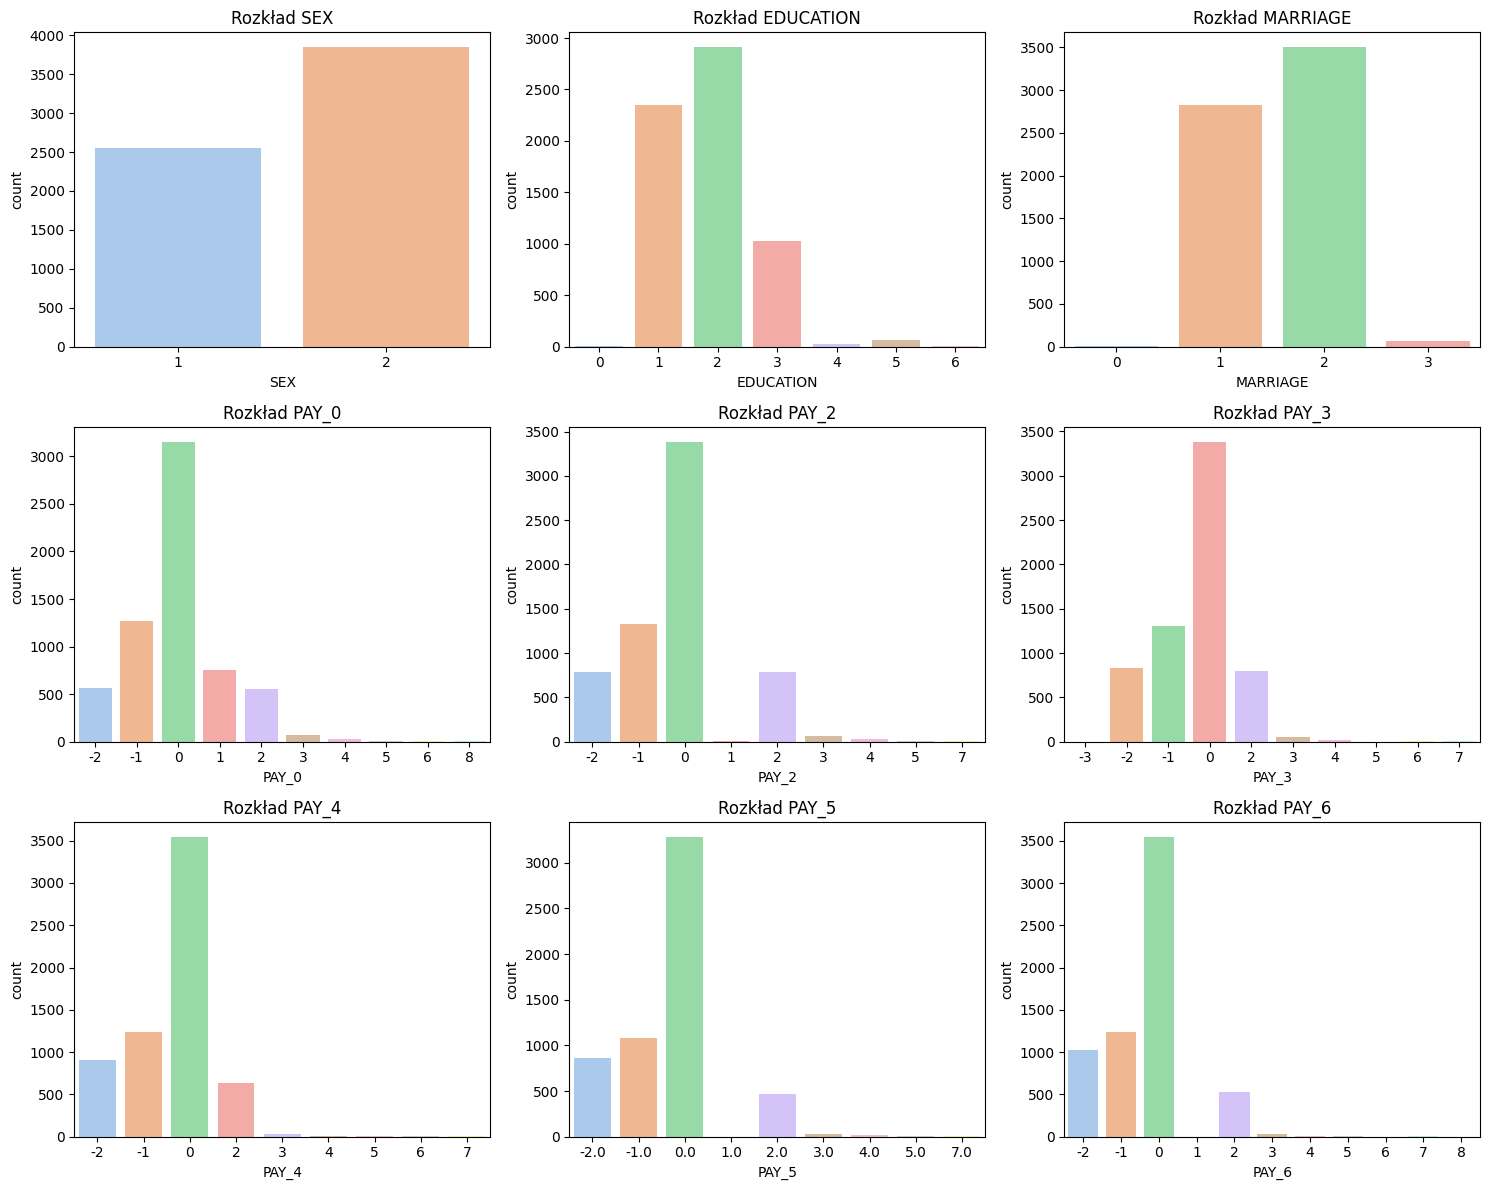

In [6]:
cat_cols = ['SEX', 'EDUCATION', 'MARRIAGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, col in zip(axes.flatten(), cat_cols):
    sns.countplot(data=X_train, x=col, ax=ax, palette='pastel')
    ax.set_title(f'Rozkład {col}')
plt.tight_layout()
plt.show()

Rozkłady PAY są prawostronnie skośne

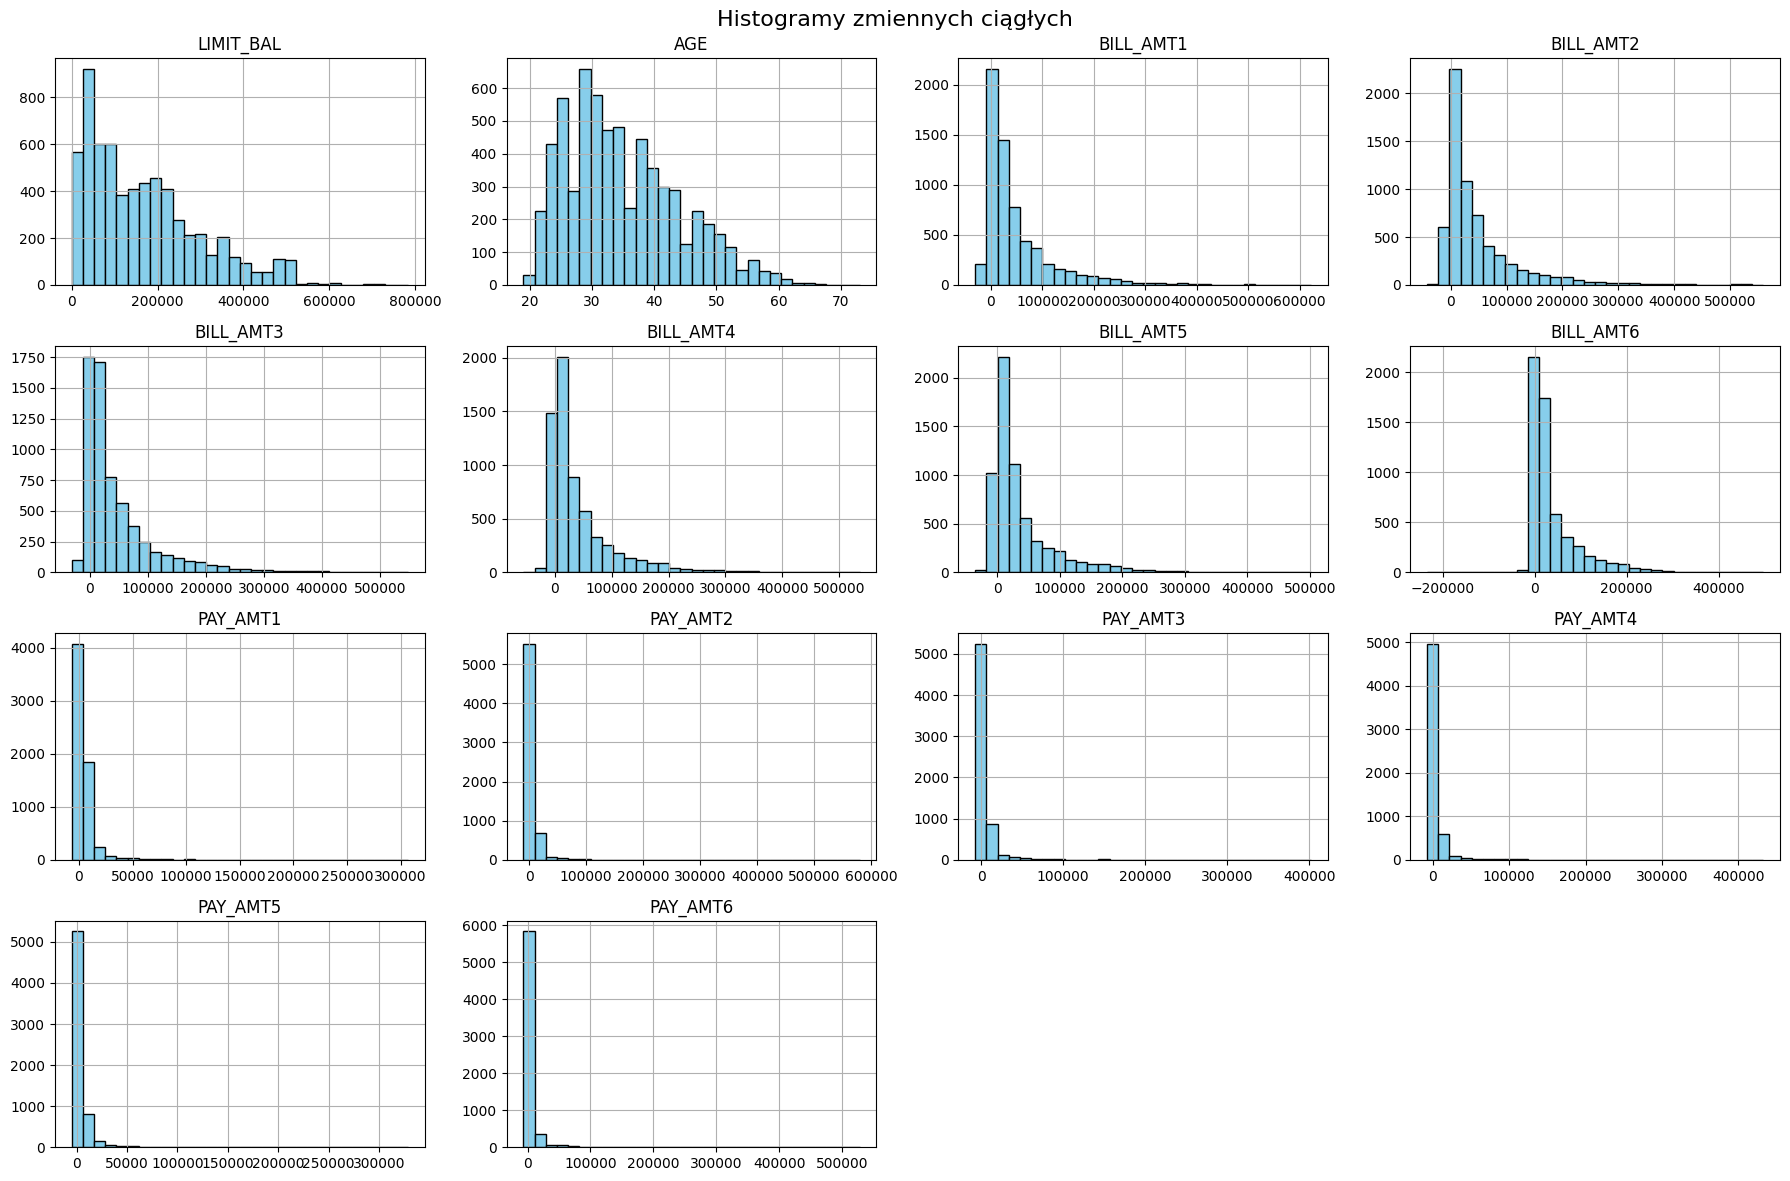

In [7]:

num_cols = ['LIMIT_BAL', 'AGE'] + [f'BILL_AMT{i}' for i in range(1, 7)] + [f'PAY_AMT{i}' for i in range(1, 7)]


X_train[num_cols].hist(bins=30, figsize=(18, 12), color='skyblue', edgecolor='black')
plt.suptitle('Histogramy zmiennych ciągłych', fontsize=16)
plt.tight_layout()
plt.show()

Wszystkie rozkłady numeryczne są prawostronnie skośne

In [8]:
print("JAWNE BRAKI DANYCH")
missing_count = X_train.isna().sum()
missing_percent = (X_train.isna().mean() * 100).round(2)

missing_df = pd.DataFrame({'Liczba braków': missing_count, 'Procent (%)': missing_percent})
display(missing_df[missing_df['Liczba braków'] > 0])

JAWNE BRAKI DANYCH


,Liczba braków,Procent (%)
PAY_5,636,9.94
BILL_AMT6,653,10.20
PAY_AMT4,635,9.92


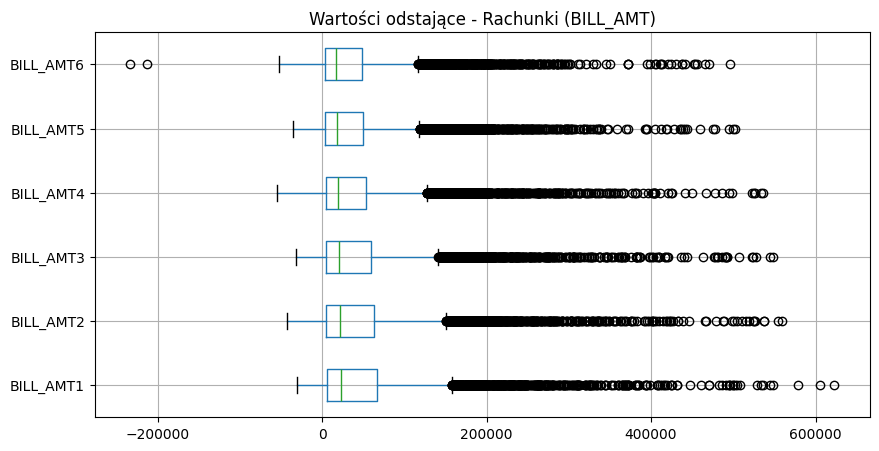

In [9]:
plt.figure(figsize=(10, 5))
X_train[[c for c in X_train.columns if c.startswith('BILL_AMT')]].boxplot(vert=False)
plt.title('Wartości odstające - Rachunki (BILL_AMT)')
plt.show()

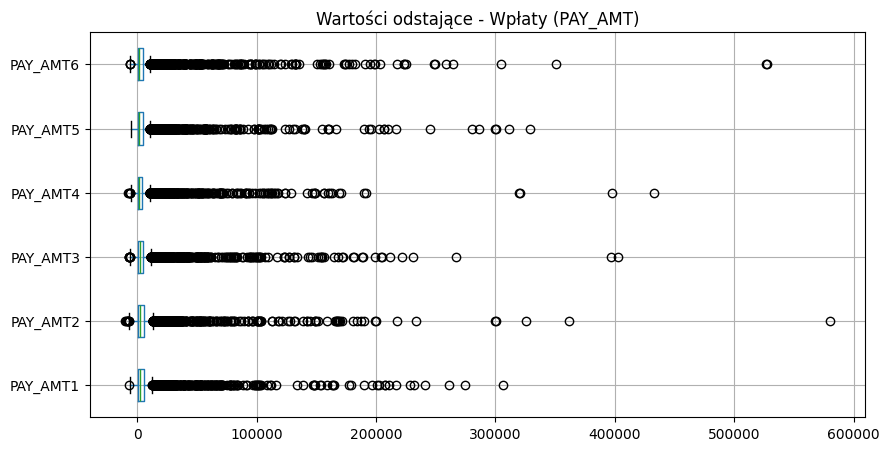

In [10]:
plt.figure(figsize=(10, 5))
X_train[[c for c in X_train.columns if c.startswith('PAY_AMT')]].boxplot(vert=False)
plt.title('Wartości odstające - Wpłaty (PAY_AMT)')
plt.show()

Zarówno BILL_AMT jak i PAY_AMT ma ogromne ilości outlierów

### *1.2 Korelacje*

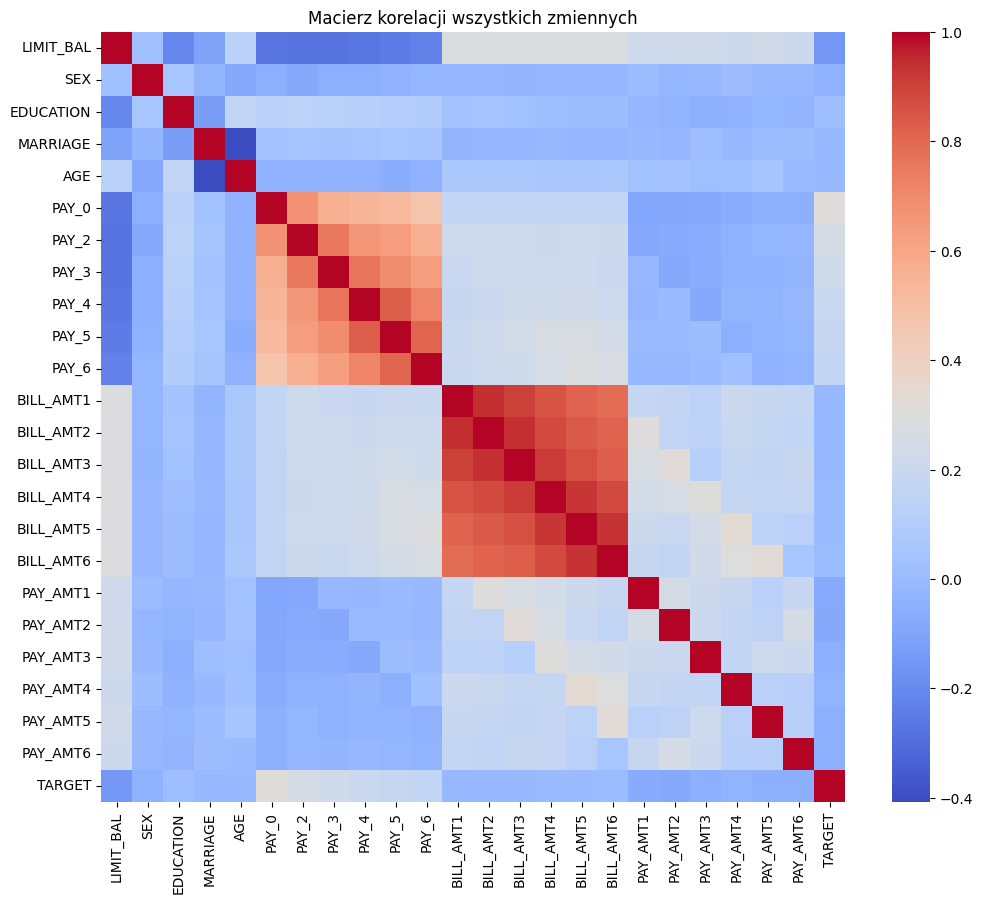

In [12]:
plt.figure(figsize=(12, 10))
corr = df.corr(numeric_only=True)

sns.heatmap(corr, cmap='coolwarm')
plt.title('Macierz korelacji wszystkich zmiennych')
plt.show()

Widzimy że BILL_AMT dla jednego klienta utrzymuje sie na podobnym poziomie z miesiąca na miesiąc.
Mamy dodatnią korelacje z PAY oraz Targetem, najsilniejsza w PAY_0.
Z korelacji LIMIT_BALL oraz Targetu widać że klienci którzy dostają wyższe limity, czyli pewnie już wczesniej są zaufani, rzadziej nie spłacają zadłużenia

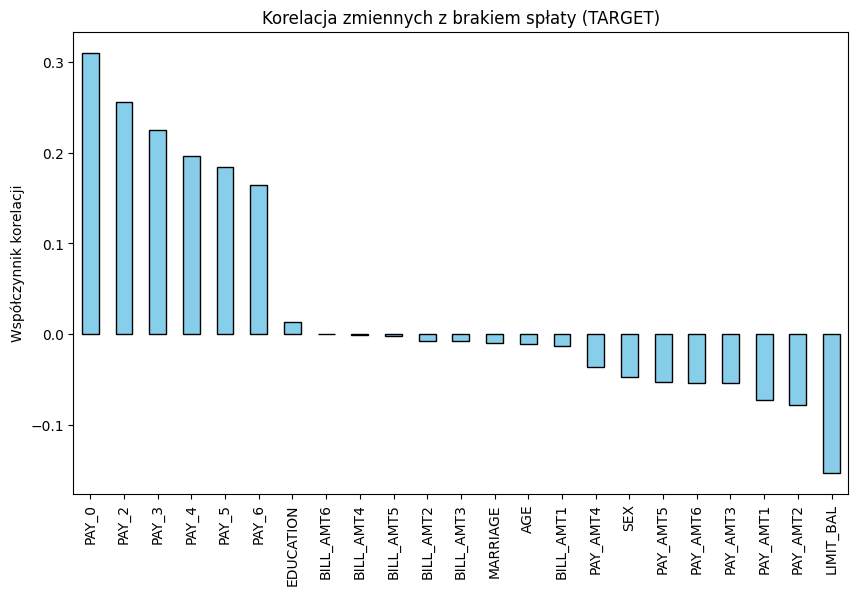

In [11]:
plt.figure(figsize=(10, 6))

target_corr = corr['TARGET'].sort_values(ascending=False).drop('TARGET')

target_corr.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Korelacja zmiennych z brakiem spłaty (TARGET)')
plt.ylabel('Współczynnik korelacji')
plt.show()

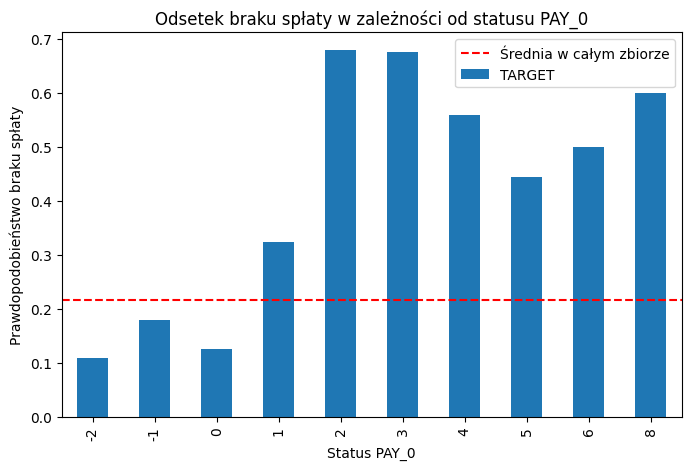

In [12]:
plt.figure(figsize=(8, 5))
df.groupby('PAY_0')['TARGET'].mean().plot(kind='bar')

plt.title('Odsetek braku spłaty w zależności od statusu PAY_0')
plt.xlabel('Status PAY_0')
plt.ylabel('Prawdopodobieństwo braku spłaty')
plt.axhline(df['TARGET'].mean(), color='red', linestyle='--', label='Średnia w całym zbiorze')
plt.legend()
plt.show()

Klienci którzy już w PAY_0 mieli zaległości w opłatach zdecydowanie częsciej nie płacą również później



### *2. Metryka ewaluacji i podział danych*
-------

In [32]:
X_model = df.drop(columns=['TARGET'])
y_model = df['TARGET']

X_train_local, X_test_local, y_train_local, y_test_local = train_test_split(
    X_model, y_model, test_size=0.2, random_state=1, stratify=y_model
)

### *2.1 Wybór metryki i optymalizacja hiperparametrów*
-------

Najlepsze parametry: {'max_depth': 12, 'min_samples_leaf': 90}
ROC AUC na teście: 0.7205
PR AUC na teście: 0.4743


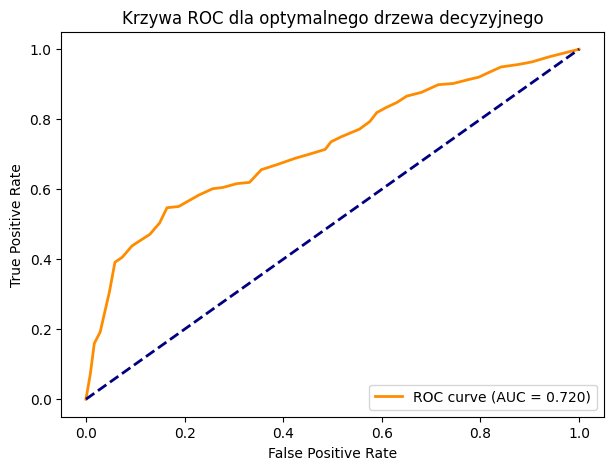

In [ ]:
param_grid = {
    'max_depth': [2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 14, 16, 18, 20, 30 ,40],
    'min_samples_leaf': [5, 7, 9 ,11, 15, 20, 25, 30 ,35, 40, 45, 50, 60, 70, 80, 90, 100, 150, 200, 300]
}

grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=123),
    param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)
grid_search.fit(X_train_local, y_train_local)
best_tree = grid_search.best_estimator_

y_score = best_tree.predict_proba(X_test_local)[:, 1]

roc_auc_val = roc_auc_score(y_test_local, y_score)
pr_auc_val = average_precision_score(y_test_local, y_score)

print(f"Najlepsze parametry: {grid_search.best_params_}")
print(f"ROC AUC na teście: {roc_auc_val:.4f}")
print(f"PR AUC na teście: {pr_auc_val:.4f}")

fpr, tpr, _ = roc_curve(y_test_local, y_score)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc_val:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Krzywa ROC dla optymalnego drzewa decyzyjnego')
plt.legend(loc="lower right")
plt.show()

ROC AUC Została wybrana jako główna metryka optymalizacyjna, ponieważ całościowo ocenia zdolność klasyfikatora do separacji klas niezależnie od progu decyzyjnego.

Zmienna docelowa charakteryzuje się wyraźnym niezbalansowaniem. W takiej sytuacji metryka ROC AUC może być nadmiernie optymistyczna, ponieważ jest pompowana przez dużą liczbę poprawnie przewidzianych klientów terminowych. Metryka PR AUC została dodana jako metryka pomocnicza ponieważ skupia się wyłącznie na klasie mniejszościowej. Pozwala to rzetelnie ocenić, jak dobrze model radzi sobie z głównym celem biznesowym czyli wyłapywaniem faktycznych dłużników.

Wybór parametrów max_depth = 12 oraz min_samples_leaf = 90 wskazuje, że siatka wymusiła na drzewie zachowawczą strukturę z bardzo pojemnymi węzłami końcowymi. Wymóg aż 90 obserwacji w liściu skutecznie uodpornił model na przeuczenie, uniemożliwiając mu tworzenie reguł decyzyjnych na podstawie pojedynczych profili klientów.

### *3. Podsumowanie i wnioski*
-------

Kluczowe będzie zaimputowanie braków danych oraz systemowa obsługa nielogicznych anomalii finansowych.

Zoptymalizowane drzewo decyzyjne (max_depth=12, min_samples_leaf=90) osiągnęło wynik ROC AUC na poziomie 0.7205 na surowym zbiorze testowym, tworząc stabilny punkt odniesienia przed wdrożeniem zaawansowanych algorytmów
.
